In [1]:
import os
import numpy as np
import random
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import pandas as pd

from glob import glob
from tqdm import tqdm
from PIL import Image, ImageOps
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from torchvision import tv_tensors
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as TVF
from torchvision import models
import torch.nn.functional as F

import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor, StochasticWeightAveraging
from lightning.pytorch.loggers import CSVLogger

from skimage import io
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE

# 3 OpenSet classification model

## Model architecture definition

For a resolving of the Open-Set classification task in the scope of our research we utilized an Class Anchor Clustering approach [1], where as an encoder has been utilized a novel pretrained transformer-based neural network DINOv2[2] with embedding vector size of 384 (the smallest version) and a Fully-Connected layer as classsification layer.

***References:*** 

[1] D. Miller, N. Suenderhauf, M. Milford, and F. Dayoub, ‘Class Anchor Clustering: A Loss for Distance-Based Open Set Recognition’, in Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision, pp. 3570–3578.

[2] M. Oquab et al., ‘DINOv2: Learning Robust Visual Features without Supervision’, arXiv:2304. 07193. 2023.


```
@misc{oquab2023dinov2,
  title={DINOv2: Learning Robust Visual Features without Supervision},
  author={Oquab, Maxime and Darcet, Timothée and Moutakanni, Theo and Vo, Huy and Szafraniec, Marc and Khalidov, Vasil and Fernandez, Pierre and Haziza, Daniel and Massa, Francisco and El-Nouby, Alaaeldin and Howes, Russell and Huang, Po-Yao and Xu, Hu and Sharma, Vasu and Li, Shang-Wen and Galuba, Wojciech and Rabbat, Mike and Assran, Mido and Ballas, Nicolas and Synnaeve, Gabriel and Misra, Ishan and Jegou, Herve and Mairal, Julien and Labatut, Patrick and Joulin, Armand and Bojanowski, Piotr},
  journal={arXiv:2304.07193},
  year={2023}
}

@inproceedings{millerclass,
  title={Class Anchor Clustering: A Loss for Distance-Based Open Set Recognition},
  author={Miller, Dimity and Suenderhauf, Niko and Milford, Michael and Dayoub, Feras},
  booktitle={Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision},
  pages={3570--3578}
}
```

In [2]:
from common.configuration import DatasetPath, ModelPath, species_native, species_invasive, species_label_map_all, species_classes_map_all

## Dataset

In [3]:
OBJECTS_ROOT = DatasetPath.objects_clean

In [4]:
from common.img_utils import pad2size, scale2factor


class PollenClassificationDataset(Dataset):
    def __init__(self, dataset,
                 classes_map,
                 known_classes,
                 static_transform=None,
                 random_transform=None):
        self.classes_map = classes_map
        self.transform = random_transform
        self.known_classes = known_classes
        self._all_samples = []
        self.class_to_index_remap = {}
        for i, c in enumerate(self.known_classes):
            self.class_to_index_remap[classes_map[c]] = i
        self.index_to_class_remap = {v: k for k,
                                     v in self.class_to_index_remap.items()}

        total_samples = 0
        for idx, sample in enumerate(tqdm(dataset)):
            img = Image.open(sample["image"])
            if sample["label"] in classes_map:
                c_number = classes_map[sample["label"]]
            else:
                c_number = -1
                raise ValueError(f"Unknown class name: {sample['label']}")
            if static_transform is not None:
                img = static_transform(img)
            self._all_samples.append((c_number, img))
            total_samples += 1
        print(f"Total samples: {total_samples}")

    def __len__(self):
        return len(self._all_samples)

    def __getitem__(self, idx):
        if idx >= len(self._all_samples):
            raise IndexError("Index out of range")
        c_number, image = self._all_samples[idx]
        label = self.class_to_index_remap[c_number]

        if self.transform:
            image = self.transform(image)

        image = torch.as_tensor(image) if not isinstance(
            image, torch.Tensor) else image
        label = torch.as_tensor(label) if not isinstance(
            label, torch.Tensor) else label

        return image, label.long(), c_number

In [5]:
species_label_map_all

{0: 'Acer',
 1: 'Alnus',
 2: 'Apiaceae',
 3: 'Artemisia',
 4: 'Betula',
 5: 'Chenopodiaceae',
 6: 'Corylus',
 7: 'Fraxinus',
 8: 'Picea',
 9: 'Pinus',
 10: 'Plantago',
 11: 'Poaceae',
 12: 'Populus tremula',
 13: 'Quercus',
 14: 'Rumex',
 15: 'Salix',
 16: 'Tilia',
 17: 'Urtica',
 18: 'Ulmus',
 19: 'Ambrosia',
 20: 'Taraxacum',
 21: 'Malus',
 -1: 'Unknown'}

In [6]:
def load_dataset(data_dir: str, train_classes: list, pseudo_unknown_classes: list, classes_map: dict) -> tuple:
    trainval_dataset = []
    test_index_dataset = []
    test_dataset = []
    for c in tqdm(train_classes + pseudo_unknown_classes):
        if not os.path.isdir(os.path.join(data_dir, c)):
            continue
        images = glob(os.path.join(data_dir, c, "*.png"))
        names = [os.path.split(n)[1].rsplit("_", maxsplit=1)[0]
                 for n in images]
        names.sort()
        names = list(set(names))
        trainval_pictures, test_pictures = names, []
        # train_test_split(
        #     names, test_size=0.2, random_state=42)

        for pic in trainval_pictures:
            trainval_img = glob(os.path.join(data_dir, c, f"{pic}*.png"))
            if c in train_classes:  # Add only selected classes to the training set
                trainval_dataset.extend(
                    [{"label": c, "image": im} for im in trainval_img])
                test_index_dataset.extend(
                    [{"label": c, "image": im} for im in trainval_img])

        for pic in test_pictures:
            test_img = glob(os.path.join(data_dir, c, f"{pic}*.png"))
            test_dataset.extend([{"label": c, "image": im} for im in test_img])

    print(f"Known train classes: {train_classes}")
    print(f"Pseudo unknown classes (for test): {pseudo_unknown_classes}")

    train_dataset, val_dataset = train_test_split(
        trainval_dataset, test_size=0.2, random_state=42)
    print(f"Train dataset size: {len(train_dataset)}")
    print(f"Validation dataset size: {len(val_dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")

    static_transforms = v2.Compose([
        v2.Lambda(scale2factor),
        v2.Lambda(pad2size),
    ])

    train_dinamic_transforms = v2.Compose([
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandomEqualize(),
        v2.RandomVerticalFlip(p=0.5),
        v2.RandomRotation(180),
        v2.RandomAutocontrast(),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    val_dinamic_transforms = v2.Compose([
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    print("\nLoad Train Dataset")
    dataset_train = PollenClassificationDataset(
        train_dataset,
        classes_map,
        train_classes,
        static_transform=static_transforms,
        random_transform=train_dinamic_transforms)
    print("\nLoad Validation Dataset")
    dataset_val = PollenClassificationDataset(
        val_dataset,
        classes_map,
        train_classes,
        static_transform=static_transforms,
        random_transform=val_dinamic_transforms)
    print("\nLoad Test Dataset")
    dataset_index_test = PollenClassificationDataset(
        test_index_dataset,
        classes_map,
        train_classes + pseudo_unknown_classes,
        static_transform=static_transforms,
        random_transform=val_dinamic_transforms)
    dataset_test = PollenClassificationDataset(
        test_dataset, 
        classes_map, 
        train_classes + pseudo_unknown_classes,
        static_transform=static_transforms, 
        random_transform=val_dinamic_transforms)
    return dataset_train, dataset_val, dataset_test, dataset_index_test


dataset_train, dataset_val, dataset_test, dataset_index_test = load_dataset(
    OBJECTS_ROOT, species_native, species_invasive, species_classes_map_all)

100%|██████████| 22/22 [00:00<00:00, 30.00it/s]


Known train classes: ['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Fraxinus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Urtica', 'Ulmus', 'Ambrosia']
Pseudo unknown classes (for test): ['Taraxacum', 'Malus']
Train dataset size: 2351
Validation dataset size: 588
Test dataset size: 0

Load Train Dataset


100%|██████████| 2351/2351 [00:20<00:00, 116.42it/s]


Total samples: 2351

Load Validation Dataset


100%|██████████| 588/588 [00:05<00:00, 113.45it/s]


Total samples: 588

Load Test Dataset


100%|██████████| 2939/2939 [00:06<00:00, 421.69it/s]


Total samples: 2939


0it [00:00, ?it/s]

Total samples: 0


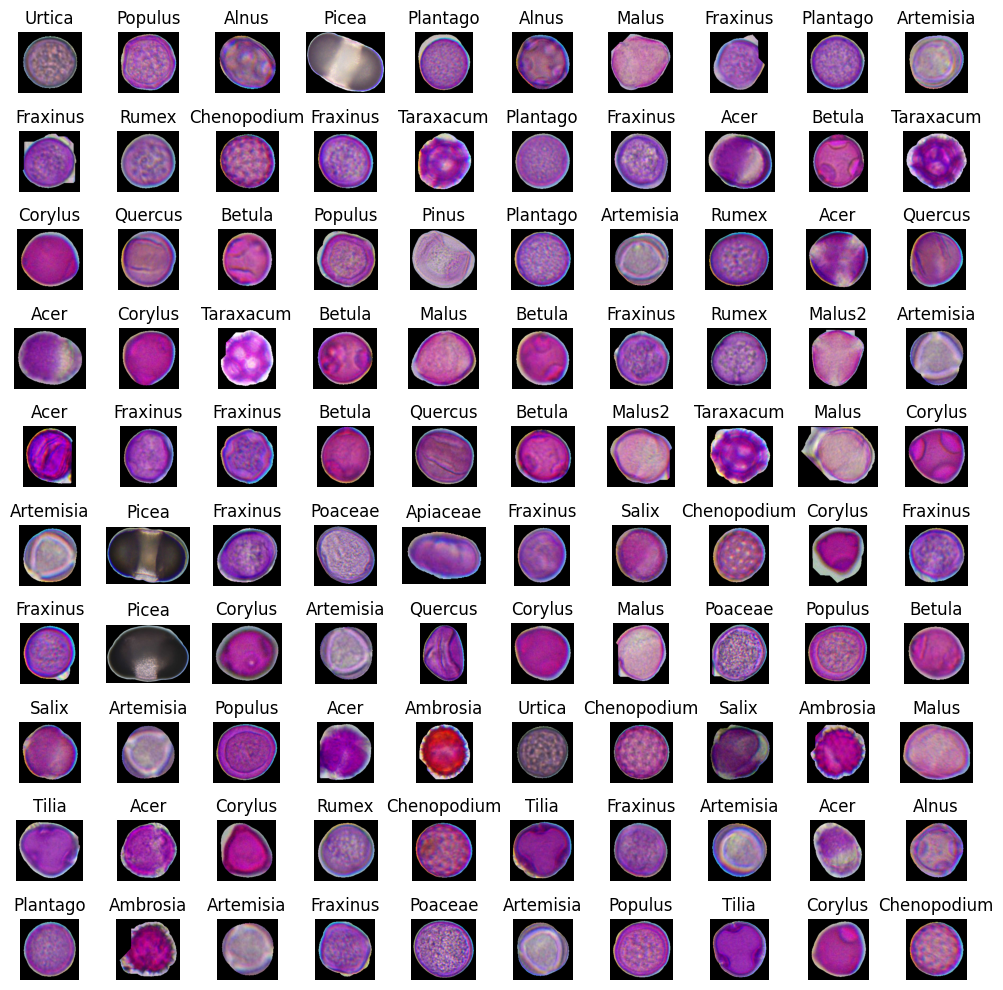

In [7]:
all_obj_images = glob(os.path.join(OBJECTS_ROOT,  "**", "*.png"), recursive=True)
all_obj_images = random.sample(all_obj_images, 100)
fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(10, 10))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    ax.set_title(os.path.basename(img_path).split(" ")[0].split("_")[0])
    ax.imshow(image_rgb)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Utils

In [8]:
def plot(imgs, row_title=None, labels=None, **imshow_kwargs):
    if labels != None:
        ax_title = True
    else:
        ax_title = False
    if not isinstance(imgs[0], list):
        # Make a 2d grid even if there's just 1 row
        imgs = [imgs]

    num_rows = len(imgs)
    num_cols = len(imgs[0])
    _, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
    for row_idx, row in enumerate(imgs):
        for col_idx, img in enumerate(row):
            boxes = None
            masks = None
            if isinstance(img, tuple):
                img, target = img
                if isinstance(target, dict):
                    boxes = target.get("boxes")
                    masks = target.get("masks")
                elif isinstance(target, tv_tensors.BoundingBoxes):
                    boxes = target
                else:
                    raise ValueError(f"Unexpected target type: {type(target)}")
            img = TVF.to_image(img)
            if img.dtype.is_floating_point and img.min() < 0:
                # Poor man's re-normalization for the colors to be OK-ish. This
                # is useful for images coming out of Normalize()
                img -= img.min()
                img /= img.max()

            img = TVF.to_dtype(img, torch.uint8, scale=True)
            black_pixels = (img != 0).all(dim=0)
            img[:, ~black_pixels] = 255
            if boxes is not None:
                img = draw_bounding_boxes(img, boxes, colors="yellow", width=3)
            if masks is not None:
                img = draw_segmentation_masks(img, masks.to(torch.bool), colors=["green"] * masks.shape[0], alpha=.65)

            ax = axs[row_idx, col_idx]
            ax.imshow(img.permute(1, 2, 0).numpy(), **imshow_kwargs)
            ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
            if ax_title:
                ax.set_title(labels[col_idx])

    if row_title is not None:
        for row_idx in range(num_rows):
            axs[row_idx, 0].set(ylabel=row_title[row_idx])

    plt.tight_layout()

## Neural Network Training 

In [9]:
train_loader = torch.utils.data.DataLoader(
    dataset_train,
    batch_size=96,
    shuffle=True,
    num_workers=0 if os.name == 'nt' else 6
)
val_loader = torch.utils.data.DataLoader(
    dataset_val,
    batch_size=4,
    shuffle=False,
    num_workers=0 if os.name == 'nt' else 6
)
test_loader = torch.utils.data.DataLoader(
    dataset_test,
    batch_size=6,
    shuffle=False,
    num_workers=0 if os.name == 'nt' else 6
)

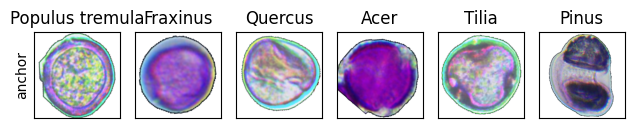

In [10]:
for image, label, c_number in train_loader:
    plot(image[:6], row_title=["anchor"], labels=[species_label_map_all[l.item()] for l in label[:6]])
    break

Import the model definition from the common module.

In [11]:
from common.osc_classification import OpenSetClassificationModel

Next, define CACLoss

In [12]:
class CACLoss(nn.Module):
    def __init__(self, num_known_classes, lbda=0.1):
        super().__init__()
        self.num_known_classes = num_known_classes
        self.lbda = lbda

    def forward(self, distances, gt):
        '''Returns CAC loss, as well as the Anchor and Tuplet loss components separately for visualisation.'''
        true = torch.gather(distances, 1, gt.view(-1, 1)).view(-1)
        non_gt = torch.Tensor([[i for i in range(self.num_known_classes) if gt[x] != i] for x in range(len(distances))]).long().cuda()
        others = torch.gather(distances, 1, non_gt)
    	
        anchor = torch.sum(true)
    
        tuplet = torch.exp(-others+true.unsqueeze(1))
        tuplet = torch.sum(torch.log(1+torch.sum(tuplet, dim = 1)))
    
        total = self.lbda*anchor + tuplet
    
        return total, anchor, tuplet

To simplification of the tarining process, we used a pytorch lightning, thus, define a wrapper for the model.

In [13]:
class PollenOSCEmbeddingsModule(L.LightningModule):
    def __init__(self,
                 n_classes,
                 alpha=20, # Magnitude of the anchor point
                 optim_lr=0.001,
                 optim_betas=(0.9, 0.999),
                 optim_eps=1e-08,
                 optim_weight_decay=0.01,
                 check_val=20,
                 freeze_epochs=10):
        super().__init__()
        # call this to save (arguments) to the checkpoint
        self.save_hyperparameters()
        self.lr = optim_lr

        self.cac_loss = CACLoss(n_classes)
        
        self.best_score = 1
        self.best_val_epoch = -1

        self.model = OpenSetClassificationModel(n_classes=n_classes)
        
        # initialising with anchors
        anchors = torch.diag(torch.Tensor([alpha for i in range(n_classes)]))	
        self.model.set_anchors(anchors)

        self.train_step_outputs = []
        self.val_step_outputs = []
        self.test_step_outputs = []
        self.train_losses = []
        self.val_losses = []
        self.test_losses = []

        self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.model.model.parameters():
            param.requires_grad = False

    def unfreeze_all(self):
        for param in self.model.parameters():
            param.requires_grad = True

    def on_train_epoch_start(self):
        pass
        # if self.current_epoch == self.hparams.freeze_epochs:
        #     self.unfreeze_all()

    def forward(self, inputs):
        return self.model(inputs)

    def _shared_eval_step(self, batch, batch_idx):
        anchor, label, c_number = batch
        l_anchor = len(anchor)
        outputs = self.model(anchor)
        loss, anchorLoss, tupletLoss = self.cac_loss(outputs[1], label)
        return loss, l_anchor

    def training_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"train_loss": loss, "train_number": l_anchor_out}
        self.train_step_outputs.append(pred)
        return loss

    def on_train_epoch_end(self):
        outputs = self.train_step_outputs
        train_loss, num_items = 0, 0
        for output in outputs:
            train_loss += output["train_loss"].sum().item()
            num_items += output["train_number"]

        mean_train_loss = torch.tensor(train_loss / num_items)
        self.log("train_loss", mean_train_loss)
        self.train_losses.append(mean_train_loss.item())
        self.train_step_outputs.clear()  # free memory

    def validation_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"val_loss": loss, "val_number": l_anchor_out}
        self.val_step_outputs.append(pred)

    def on_validation_epoch_end(self):
        outputs = self.val_step_outputs
        val_loss, num_items = 0, 0
        for output in outputs:
            val_loss += output["val_loss"].sum().item()
            num_items += output["val_number"]

        mean_val_loss = torch.tensor(val_loss / num_items)
        self.val_losses.append(mean_val_loss.item())
        self.val_step_outputs.clear()  # free memory
        
        tensorboard_logs = {
            "val_loss": mean_val_loss
        }
        self.log("val_loss", mean_val_loss)

        if mean_val_loss < self.best_score:
            self.best_score = mean_val_loss
            self.best_val_epoch = self.current_epoch

    def test_step(self, batch, batch_idx):
        anchor, label, c_number = batch
        anchor_emb, anchor_out = self.model(anchor)
        celoss = self.celoss(anchor_out, label)
        loss = celoss
        l_anchor_out = len(anchor_out)

        true_pred = 0
        for i,l in enumerate(label):
            if torch.argmax(l).item() == torch.argmax(anchor_out).item():
                true_pred += 1
        acc = true_pred / l_anchor_out
        pred = {"test_loss": loss, "test_number": l_anchor_out, "test_acc": acc}
        self.test_step_outputs.append(pred)

    def on_test_epoch_end(self):
        outputs = self.test_step_outputs
        test_loss, num_items, test_acc = 0, 0, 0
        for output in outputs:
            test_loss += output["test_loss"].sum().item()
            num_items += output["test_number"]
            test_acc += output["test_acc"]
        mean_test_loss = torch.tensor(test_loss / num_items)
        mean_test_acc = torch.tensor(test_acc / len(outputs))
        print('mean_test_loss', mean_test_loss)
        print('mean_test_acc', mean_test_acc)
        self.test_losses.append(mean_test_loss.item())
        self.log('mean_test_loss', mean_test_loss)
        self.log('mean_test_acc', mean_test_acc)
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        
        self.optimizer = torch.optim.Adagrad(
            [
                {'params': self.model.model.parameters(), 'lr': 0.0},
                {'params': self.model.classifier.parameters(), 'lr': self.lr},
            ],
            lr=self.lr,
            eps=self.hparams.optim_eps,
            weight_decay=self.hparams.optim_weight_decay
        )
        return {
            "optimizer": self.optimizer,
            "lr_scheduler": {
                "scheduler": ReduceLROnPlateau(self.optimizer, factor=0.3, patience=5),
                "frequency": self.hparams.check_val,
                "monitor": "val_loss",
                "interval": "epoch",
            }
        }

    def plot_losses(self):
        plt.figure(figsize=(10, 5))
        plt.plot([i for i in range(len(self.train_losses))], self.train_losses, label='Train Loss')
        plt.plot([i * self.hparams.check_val for i in range(len(self.val_losses))], self.val_losses, label='Validation Loss')
        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Training and Validation Losses')
        plt.legend()
        plt.show()

Create and prepare for training an instance of the Model.

In [14]:
model = PollenOSCEmbeddingsModule(n_classes=len(species_native), check_val=1, freeze_epochs=30) # Do not train backbone
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Use device: {device}")
model = model.to(device)

Using cache found in C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Use device: cuda


Define callbacks for the training process

In [15]:
checkpoint_callback = ModelCheckpoint(
    filename='checkpoint-Adagrad-{epoch:02d}-{val_loss:.2f}',
    # auto_insert_metric_name=False,
    dirpath="./history",
    monitor='val_loss',
    mode='min')
lr_logger = LearningRateMonitor()
logger = CSVLogger("logs", name="osc_cac_loss")

swa = StochasticWeightAveraging(swa_lrs=0.01)

### Learning rate optimization

To optimize learning rate we utilized an appoach implemented in Pytorch Lightning library which is based on idea proposed by L. Smith [1]

[1] L. N. Smith, ‘Cyclical Learning Rates for Training Neural Networks’, in 2017 IEEE Winter Conference on Applications of Computer Vision (WACV), 2017, pp. 464–472.

In [16]:
trainer = L.Trainer(logger=logger,
                    log_every_n_steps=2,  # Increase, if epoch size is large
                    callbacks=[checkpoint_callback, lr_logger, swa],
                    precision="16-mixed",
                    check_val_every_n_epoch=model.hparams.check_val,
                    max_epochs=100, #100
                    # accumulate_grad_batches=2,
                    )

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.venv\lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.venv\lib\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:654: Checkpoint directory E:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\history exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
e:\Research\Automatic online monitoring of allergic pollen\Pollen

Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.venv\lib\site-packages\torch\optim\lr_scheduler.py:143: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn("Detected call of `lr_scheduler.step()` before `optimizer.step()`. "
`Trainer.fit` stopped: `max_steps=100` reached.
Learning rate set to 0.001
Restoring states from the checkpoint path at e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.lr_find_d69ebff5-3cea-4147-a0a8-4c9cba0723c7.ckpt
Restored all states from the checkpoint at e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.lr_find_d69ebff5-3cea-4147-a

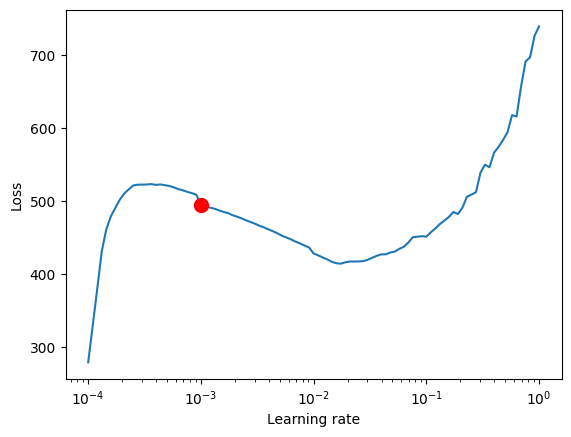

In [17]:
tuner = L.pytorch.tuner.Tuner(trainer)
lf_finder = tuner.lr_find(model,
            train_dataloaders=train_loader, min_lr= 10**-4)

fig = lf_finder.plot(suggest=True)
fig.show()

Print the suggested learning rate.

In [18]:
lf_finder.suggestion()

0.001

And hyperparameters of the network.

In [19]:
model.hparams

"alpha":              20
"check_val":          1
"freeze_epochs":      30
"n_classes":          20
"optim_betas":        (0.9, 0.999)
"optim_eps":          1e-08
"optim_lr":           0.001
"optim_weight_decay": 0.01

Next, apply LR suggestion to the model.

In [20]:
model.lr = lf_finder.suggestion()
model.hparams.optim_lr = lf_finder.suggestion()

### Training loop and results

Start a training process of the model.

In [21]:
trainer.fit(model, 
            train_dataloaders=train_loader, 
            val_dataloaders=val_loader,     
)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type                       | Params | Mode 
----------------------------------------------------------------
0 | cac_loss | CACLoss                    | 0      | train
1 | model    | OpenSetClassificationModel | 22.1 M | train
----------------------------------------------------------------
7.7 K     Trainable params
22.1 M    Non-trainable params
22.1 M    Total params
88.259    Total estimated model params size (MB)
214       Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

e:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\.venv\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


Plot curves of loss changes during training

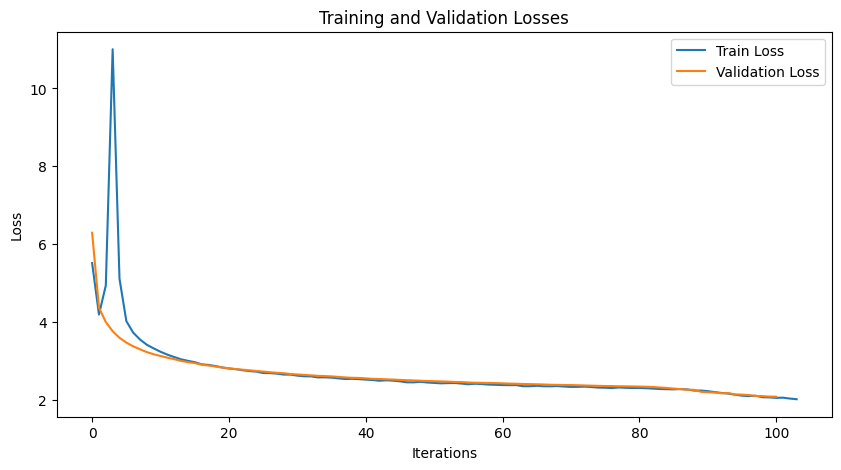

In [22]:
model.plot_losses()

## OSC NN Model Predictions Visualization

In [23]:
from common.osc_classification import distance_to_scores, scores_to_class

In [24]:
def prepare_data(embeddings_lists: list, labels_lists: list):
    all_labels_sorted = []
    all_embeddings_sorted = []
    class_boundaries = [0]
    for i, embeddings_list in enumerate(embeddings_lists):
        labels_list = labels_lists[i]
        class_to_idx = {}
        for i, class_name in enumerate(np.unique(labels_list)):
            class_to_idx[class_name] = i
        all_labels_idx = [class_to_idx[label] for label in labels_list]
        sorted_indices = sorted(range(len(embeddings_list)), key=lambda i: all_labels_idx[i])
        start = len(all_labels_sorted) + 1
        all_embeddings_sorted.extend([embeddings_list[i] for i in sorted_indices])
        all_labels_sorted.extend([labels_list[i] for i in sorted_indices])
    
        for i in range(start, len(all_labels_sorted)):
            if all_labels_sorted[i] != all_labels_sorted[i-1]:
                class_boundaries.append(i)
        class_boundaries.append(len(all_labels_sorted))

    return all_labels_sorted, all_embeddings_sorted, class_boundaries

In [25]:
def add_class_markings(ax, class_boundaries, labels):
    tick_locs = [(class_boundaries[i] + class_boundaries[i+1] - 1) / 2 for i in range(len(class_boundaries)-1)]
    ax.set_xticks(tick_locs)
    ax.set_yticks(tick_locs)
    ax.set_xticklabels([labels[int(loc)] for loc in tick_locs])
    ax.set_yticklabels([labels[int(loc)] for loc in tick_locs])
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for boundary in class_boundaries[1:-1]:
        ax.axhline(y=boundary-1, color='k', linestyle='-', linewidth=1)
        ax.axvline(x=boundary-1, color='k', linestyle='-', linewidth=1)

In [26]:
def plot_matrix(embeddings_lists: list, labels_lists: list, subtitle: str=None, axes_class_markings: bool=True):
    all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(embeddings_lists, labels_lists)

    pairwise_dist = pairwise_distances(all_embeddings_sorted, metric="euclidean")#cosine
    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(pairwise_dist, cmap='Blues_r')#, norm=PowerNorm(gamma=0.5, vmin=0, vmax=1)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    if axes_class_markings:
        add_class_markings(ax, class_boundaries, all_labels_sorted)

    if subtitle != None:
        plt.title('Pairwise Distance Matrix\n' + subtitle)
    else:
        plt.title('Pairwise Distance Matrix')
    plt.tight_layout()
    plt.show()
    del all_labels_sorted
    del all_embeddings_sorted
    del class_boundaries

In [27]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

def process_loader(model, loader):
    all_embeddings = []
    all_predictions = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            imgs, labels, c_number = batch
            labels_str = [species_label_map_all[l.item()] for l in c_number]
            
            imgs = imgs.cuda()
            embeddings, pred_distances = model(imgs)
            scores = distance_to_scores(pred_distances)
            prediction = scores_to_class(scores, 8.0)
            predict_str = [prediction_to_class_name(l.item()) for l in prediction.cpu()]
            
            all_embeddings.append(embeddings.cpu())
            all_labels.extend(labels_str)
            all_predictions.extend(predict_str)
        all_embeddings = torch.cat(all_embeddings, dim=0).cpu().numpy()
        
    return all_embeddings, all_labels, all_predictions

In [28]:
loaders_list = [test_loader, val_loader, train_loader] #test_loader, val_loader, train_loader
embeddings_data = []
labels_data_str = []
labels_predictions = []

### Feature space analysis

To analyze feature space we projected it into 2-dimentional space using T-SNE method.

## Save pure OSC model as Pytorch

In [29]:
model = PollenOSCEmbeddingsModule.load_from_checkpoint(checkpoint_callback.best_model_path)
model.eval()
torch.save(model.model.state_dict(), ModelPath.osc_classification)

Using cache found in C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main


## Evaluate performance

### Database initialization

In [30]:
from annoy import AnnoyIndex

fill the database with all samples intended to to be used for indexing

In [31]:
fs_size = len(species_native)  # Length of item vector that will be indexed

known_samples_features_db = AnnoyIndex(fs_size, "euclidean")
sample_id_to_class = []

batch_size = 6
dataset_index_test_loader = torch.utils.data.DataLoader(
    dataset_index_test,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0 if os.name == 'nt' else 6
)
model.eval()
for batch_idx, batch in tqdm(enumerate(dataset_index_test_loader)):
    images, labels, c_indexs = batch
    with torch.no_grad():
        outLinear, outDistance = model.forward(images.cuda())
        for i, (features, c_index) in enumerate(zip(outLinear.data.cpu().numpy(), c_indexs)):
            known_samples_features_db.add_item(batch_idx*batch_size + i, features)
            sample_id_to_class.append(c_index)

490it [01:32,  5.32it/s]


In [32]:
known_samples_features_db.build(10)  # 10 trees

True

In [33]:
known_samples_features_db.get_item_vector(100)

[7.116754055023193,
 3.354672431945801,
 -2.26525616645813,
 1.443926215171814,
 0.5391423106193542,
 -1.4973806142807007,
 3.2012007236480713,
 1.1593759059906006,
 3.780855655670166,
 -0.8344588279724121,
 -2.8223893642425537,
 -1.0369232892990112,
 -2.019432783126831,
 3.439227342605591,
 -3.629108190536499,
 2.7024011611938477,
 3.5873162746429443,
 -1.930635929107666,
 0.7004896402359009,
 1.6982357501983643]

### Test samples from test subset

In [34]:
from collections import Counter
from sklearn.metrics import f1_score, precision_score, recall_score


In [35]:
classification_threshold = 8.0

predictions = []
test_loader
for batch_idx, batch in tqdm(enumerate(test_loader)):
    images, labels, c_indexs = batch
    with torch.no_grad():
        outLinear, outDistance = model.forward(images.cuda())
    for i, (features, c_index) in enumerate(zip(outLinear.data.cpu().numpy(), c_indexs)):
        neighbor_ids, neighbor_dists = known_samples_features_db.get_nns_by_vector(
            features, 10, include_distances=True)
        neighbor_dists = np.array(neighbor_dists)
        if np.all(neighbor_dists < classification_threshold):
            neighbor_classes = [sample_id_to_class[neighbor_id]
                                for neighbor_id in neighbor_ids]
            most_common_class = Counter(neighbor_classes).most_common(1)[0][0]
        else:
            most_common_class = 22 # Unknown
            if species_label_map_all[c_index.item()] in species_invasive:
                most_common_class = c_index # Correct recognition of unknown class
        predictions.append({
            "predict": most_common_class,
            "label": c_index,
            "features": features})

0it [00:00, ?it/s]


In [36]:
predictions_pd = pd.DataFrame(predictions)
predictions_pd.to_csv("predictions_cac_test2.csv")

In [37]:
predictions[0]

IndexError: list index out of range

In [38]:
species_classes_map_all

{'Acer': 0,
 'Alnus': 1,
 'Apiaceae': 2,
 'Artemisia': 3,
 'Betula': 4,
 'Chenopodiaceae': 5,
 'Corylus': 6,
 'Fraxinus': 7,
 'Picea': 8,
 'Pinus': 9,
 'Plantago': 10,
 'Poaceae': 11,
 'Populus tremula': 12,
 'Quercus': 13,
 'Rumex': 14,
 'Salix': 15,
 'Tilia': 16,
 'Urtica': 17,
 'Ulmus': 18,
 'Ambrosia': 19,
 'Taraxacum': 20,
 'Malus': 21,
 'Unknown': -1}

In [39]:
species_label_map_all

{0: 'Acer',
 1: 'Alnus',
 2: 'Apiaceae',
 3: 'Artemisia',
 4: 'Betula',
 5: 'Chenopodiaceae',
 6: 'Corylus',
 7: 'Fraxinus',
 8: 'Picea',
 9: 'Pinus',
 10: 'Plantago',
 11: 'Poaceae',
 12: 'Populus tremula',
 13: 'Quercus',
 14: 'Rumex',
 15: 'Salix',
 16: 'Tilia',
 17: 'Urtica',
 18: 'Ulmus',
 19: 'Ambrosia',
 20: 'Taraxacum',
 21: 'Malus',
 -1: 'Unknown'}

In [40]:
performance_metrics = []
for idx, (prec, recall, f1) in enumerate(
    zip(precision_score([y["label"].item() for y in predictions], [y["predict"] for y in predictions], average=None),
        recall_score([y["label"].item() for y in predictions], [
                     y["predict"] for y in predictions], average=None),
        f1_score([y["label"].item() for y in predictions], [y["predict"] for y in predictions], average=None))
):
    idx = idx -1
    print(
        f"Class {species_label_map_all[idx]}: precision={prec:.3f}, recall={recall:.3f}, F1={f1:.3f}")
    performance_metrics.append({"species": species_label_map_all[idx],
                                "precision": prec,
                                "recall": recall,
                                "f1": f1})
performance_metrics.append({"species": "weighted",
                            "precision":precision_score([y["label"].item() for y in predictions], [y["predict"] for y in predictions], average="weighted"),
                            "recall":recall_score([y["label"].item() for y in predictions], [y["predict"]for y in predictions], average="weighted"),
                            "f1": f1_score([y["label"].item() for y in predictions], [y["predict"] for y in predictions], average="weighted")})
performance_metrics_pd = pd.DataFrame(performance_metrics)
performance_metrics_pd.to_csv("preformance_metrics_cac_test.csv")

In [41]:
def plot_confusion_matrix(y_true, y_pred, subtitle: str = ""):
    fig, ax = plt.subplots(figsize=(8,8))
    labels = sorted(set(y_true + y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    if len(subtitle) > 0:
        plt.title("Confusion Matrix\n" + subtitle)
    else:
        plt.title("Confusion Matrix")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.show()

In [43]:
titles = ["Validation", "Train"]
i = 0
for loader in tqdm(loaders_list):
    print("-" * 10, titles[i], "-" * 10)
    i += 1
    embeddings, labels, preds = process_loader(model.cuda(), loader)
    embeddings_data.append(embeddings)
    labels_data_str.append(labels)
    labels_predictions.append(preds)
    plot_matrix([embeddings], [labels], 'CAC Loss')
    plot_confusion_matrix(labels, preds)
    print(classification_report(labels, preds))

  0%|          | 0/3 [00:00<?, ?it/s]

---------- Validation ----------


RuntimeError: torch.cat(): expected a non-empty list of Tensors

In [ ]:
def get_cmap(n, name='hsv'):
    '''Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    RGB color; the keyword argument name must be a standard mpl colormap name.'''
    return plt.cm.get_cmap(name, n)

def plot_tsne(embeddings_data, labels_data_str, subtitle: str = None):
    class_to_indices = {c: [] for c in np.unique(labels_data_str)}
    for i, label in enumerate(labels_data_str):
        class_to_indices[label].append(i)
    vectors = np.array(embeddings_data)
    colors = get_cmap(len(class_to_indices.items()))
    
    labels = [""] * vectors.shape[0]

    for class_name, indices in class_to_indices.items():
        for index in indices:
            labels[index] = class_name
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=20, metric="euclidean", n_iter=2000, n_jobs=-1, early_exaggeration=12)#cosine
    vectors_2d = tsne.fit_transform(vectors)
    
    plt.figure(figsize=(8, 6))
    for i, (class_name, indices) in enumerate(class_to_indices.items()):
        mask = np.isin(range(vectors.shape[0]), indices)
        plt.scatter(vectors_2d[mask, 0], vectors_2d[mask, 1], 
                    label=class_name, color=colors(i), alpha=0.6)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    if subtitle: 
        plt.title("t-SNE visualization of image features\n"+subtitle)
    else:
        plt.title("t-SNE visualization of image features")
    plt.tight_layout()
    plt.show()

In [ ]:
import itertools
titles = ["test", "validation", "train", "All"]
for i, dataset in enumerate(embeddings_data + [np.vstack(embeddings_data), ]):
    plot_tsne(dataset, 
              (labels_data_str + [list(itertools.chain.from_iterable(labels_data_str)),])[i], 
              titles[i])